# Vorticity and circulation

- **Vorticity** $\omega = \partial v/\partial x - \partial u/\partial y$ — how fast a fluid
  element *spins*, not how fast it goes round.
- **Circulation** $\Gamma = \oint \mathbf{V}\cdot d\mathbf{l}$ around a closed contour.
- **Stokes:** $\Gamma = \iint \omega\, dA$ — the contour integral counts the vorticity inside it.

A potential vortex is the case that makes the difference obvious: everything orbits, nothing spins.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
plt.rcParams['animation.html'] = 'jshtml'

GAMMA, A = 2*np.pi, 0.5      # circulation, and core radius

def vortex(x, y, t, xc=0.0, yc=0.0, G=GAMMA, a=A):
    """Rankine vortex: potential (irrotational) outside r=a, solid-body core inside.
    The core is what keeps the centre from being infinitely fast."""
    dx, dy = x - xc, y - yc
    r = np.maximum(np.hypot(dx, dy), 1e-12)
    v_theta = G/(2*np.pi) * np.where(r < a, r/a**2, 1/r)
    return -v_theta*dy/r, v_theta*dx/r

U_INF = 1.5

def drifting(x, y, t):
    """The same vortex, carried downstream by a uniform stream.
    A point vortex is convected by the flow it sits in, so the core moves at U_INF too."""
    u, v = vortex(x, y, t, xc=-3.0 + U_INF*t)
    return U_INF + u, v

def vorticity(vel, x, y, t=0.0, h=1e-5):
    """omega = dv/dx - du/dy, by finite difference."""
    return (vel(x+h, y, t)[1] - vel(x-h, y, t)[1])/(2*h) \
         - (vel(x, y+h, t)[0] - vel(x, y-h, t)[0])/(2*h)

One integrator for everything. This is the **midpoint** step rather than plain Euler: forward
Euler pushes a circular orbit outwards by a factor $\sqrt{1+(\Omega\,dt)^2}$ every step, which
turns a vortex into a spiral. Midpoint costs one extra line and removes the problem.

In [ ]:
def step(vel, P, t, dt):
    """Advance particles P (an (N,2) array) by one midpoint step."""
    u1, v1 = vel(P[:, 0], P[:, 1], t)
    xm, ym = P[:, 0] + 0.5*dt*u1, P[:, 1] + 0.5*dt*v1
    u2, v2 = vel(xm, ym, t + 0.5*dt)
    return P + dt*np.column_stack([u2, v2])

def arrows(ax, vel, t, xlim, ylim, nx=17, ny=13, **kw):
    """Background arrows = the velocity field at this instant."""
    X, Y = np.meshgrid(np.linspace(*xlim, nx), np.linspace(*ylim, ny))
    U, V = vel(X, Y, t)
    opts = dict(color='0.6', width=0.006, angles='xy', scale_units='xy', scale=3)
    return ax.quiver(X, Y, U, V, **{**opts, **kw})

## 1. What the flow actually looks like

In [ ]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 3.6))

arrows(a1, vortex, 0, (-2.2, 2.2), (-2.2, 2.2), nx=13, ny=13)
a1.add_patch(plt.Circle((0, 0), A, color='C3', alpha=0.15))
a1.set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), aspect='equal', title='velocity field')

r = np.linspace(0.001, 2.2, 400)
a2.plot(r, GAMMA/(2*np.pi)*np.where(r < A, r/A**2, 1/r))
a2.axvline(A, color='C3', ls='--')
a2.set(xlabel='r', ylabel=r'$v_\theta$', title=r'$v_\theta = \Gamma/2\pi r$ outside the core')

g = np.linspace(-2.2, 2.2, 241)
X, Y = np.meshgrid(g, g)
w_core = GAMMA/(np.pi*A**2)                       # = 2 * (solid-body rotation rate)
im = a3.imshow(vorticity(vortex, X, Y), origin='lower', extent=(-2.2, 2.2, -2.2, 2.2),
               cmap='RdBu_r', vmin=-w_core, vmax=w_core)
a3.set(aspect='equal', title=r'vorticity $\omega$ — zero except in the core')
fig.colorbar(im, ax=a3)
fig.tight_layout(); plt.show()

Everything outside the shaded core is **irrotational**: $\omega = 0$, even though the fluid is
clearly going round in circles. Orbiting is not spinning.

## 1b. Drop particles in at different radii

In [ ]:
RADII = [0.25, 0.7, 1.1, 1.6]        # 0.25 sits inside the core, the rest do not
NF, SUB, DT, S = 90, 12, 0.01, 0.16

# each marker is a PADDLE WHEEL: it is carried by the flow, and it turns at the
# local rotation rate, which is omega/2.  Does it spin, or only go round?
P, spin = np.array([[r, 0.0] for r in RADII]), np.zeros(len(RADII))
hist, spins = [P.copy()], [spin.copy()]
for f in range(NF):
    for _ in range(SUB):
        spin = spin + 0.5*vorticity(vortex, P[:, 0], P[:, 1])*DT
        P = step(vortex, P, 0.0, DT)
    hist.append(P.copy()); spins.append(spin.copy())
hist, spins = np.array(hist), np.array(spins)

fig, ax = plt.subplots(figsize=(5.8, 5.8))
arrows(ax, vortex, 0, (-2.1, 2.1), (-2.1, 2.1), nx=15, ny=15)
ax.add_patch(plt.Circle((0, 0), A, color='C3', alpha=0.15))
ax.set(xlim=(-2.1, 2.1), ylim=(-2.1, 2.1), aspect='equal')
trail = [ax.plot([], [], lw=1, alpha=0.6, color=f'C{i}')[0] for i in range(len(RADII))]
arm1  = [ax.plot([], [], lw=2.5, color=f'C{i}')[0] for i in range(len(RADII))]
arm2  = [ax.plot([], [], lw=2.5, color=f'C{i}')[0] for i in range(len(RADII))]
tip   = [ax.plot([], [], 'o', ms=5, color=f'C{i}')[0] for i in range(len(RADII))]

def draw(k):
    for i in range(len(RADII)):
        cx, cy, a = hist[k, i, 0], hist[k, i, 1], spins[k, i]
        ca, sa = S*np.cos(a), S*np.sin(a)
        arm1[i].set_data([cx-ca, cx+ca], [cy-sa, cy+sa])
        arm2[i].set_data([cx+sa, cx-sa], [cy-ca, cy+ca])
        tip[i].set_data([cx+ca], [cy+sa])
        trail[i].set_data(hist[:k+1, i, 0], hist[:k+1, i, 1])
    ax.set_title(f't = {k*SUB*DT:.1f}')

plt.close(fig)
FuncAnimation(fig, draw, frames=NF+1, interval=60)

Two things to point out:

* **Orbit time grows like $r^2$** ($T = 2\pi r/v_\theta = 4\pi^2 r^2/\Gamma$), so the inner
  markers lap the outer ones many times over.
* **Only the marker inside the core spins.** The outer crosses get *sheared* — one arm tips
  forward, the other tips back by the same amount — so their average orientation never changes.
  That cancellation is exactly $\omega = 0$.

## 2. The same vortex, drifting downstream

In [ ]:
NF, SUB, DT = 110, 4, 0.01
OFFSETS = [0.4, 0.7, 1.1, 1.6]        # starting distance above the core

P = np.array([[-3.0, d] for d in OFFSETS])   # each starts directly above the core
hist, t = [P.copy()], 0.0
for f in range(NF):
    for _ in range(SUB):
        P = step(drifting, P, t, DT); t += DT
    hist.append(P.copy())
hist = np.array(hist)

fig, ax = plt.subplots(figsize=(10, 5.2))
q = arrows(ax, drifting, 0, (-3.6, 3.6), (-2.0, 2.0), nx=19, ny=11, scale=5)
ax.set(xlim=(-3.8, 3.8), ylim=(-2.1, 2.1), aspect='equal')
core,  = ax.plot([], [], 'o', color='C3', ms=10, label='vortex core')
ctr,   = ax.plot([], [], lw=1, ls='--', color='C3', alpha=0.6)
pts    = [ax.plot([], [], 'o', ms=7, color=f'C{i}')[0] for i in range(len(OFFSETS))]
trails = [ax.plot([], [], lw=1.2, color=f'C{i}', label=f'started {d} above core')[0]
          for i, d in enumerate(OFFSETS)]
ax.legend(loc='lower left', fontsize=8)

def draw(k):
    tk = k*SUB*DT
    xc = -3.0 + U_INF*tk
    q.set_UVC(*drifting(q.X, q.Y, tk))
    core.set_data([xc], [0]); ctr.set_data([-3.0, xc], [0, 0])
    for i in range(len(OFFSETS)):
        pts[i].set_data(hist[k, i, 0:1], hist[k, i, 1:2])
        trails[i].set_data(hist[:k+1, i, 0], hist[:k+1, i, 1])
    ax.set_title(f't = {tk:.1f}')

plt.close(fig)
FuncAnimation(fig, draw, frames=NF+1, interval=60)

The core is convected by the stream at exactly $U_\infty$, so it never overtakes the fluid
around it — **in a frame riding with the core this is just the steady vortex of Part 1.** What
you see in the lab frame is that steady orbiting *plus* a uniform drift, which is why the paths
come out as loops: a particle close in loops several times while being carried downstream, and
one further out only manages a gentle wave. Orbit time still goes like $r^2$.

This flow is unsteady in the lab frame, so (Tutorial 1) its streamlines, pathlines and
streaklines are all different curves. Change frame and it becomes steady, and they collapse
onto one. Steadiness is a property of the observer, not the flow.

## 3. Circulation: integrating round a contour

In [ ]:
def circulation(vel, xs, ys, t=0.0):
    """Gamma = closed integral of V.dl around the polygon (xs, ys), by the midpoint rule."""
    dx, dy = np.roll(xs, -1) - xs, np.roll(ys, -1) - ys
    xm, ym = xs + 0.5*dx, ys + 0.5*dy          # segment midpoints
    u, v = vel(xm, ym, t)
    return np.sum(u*dx + v*dy)

def refine(xs, ys, n=600):
    """Resample a polygon onto n short segments, so the line integral is accurate.
    A 4-vertex square integrated as 4 long segments is ~27% out; refined it is exact."""
    xs, ys = np.append(xs, xs[0]), np.append(ys, ys[0])
    d = np.concatenate([[0], np.cumsum(np.hypot(np.diff(xs), np.diff(ys)))])
    sd = np.linspace(0, d[-1], n, endpoint=False)
    return np.interp(sd, d, xs), np.interp(sd, d, ys)

def circle(R, cx=0.0, cy=0.0, n=240):
    th = np.linspace(0, 2*np.pi, n, endpoint=False)
    return cx + R*np.cos(th), cy + R*np.sin(th)

th = np.linspace(0, 2*np.pi, 240, endpoint=False)
contours = {
    'circle, encloses core':      circle(1.5),
    'circle, misses core':        circle(0.6, cx=1.5),
    'square, encloses core':      (np.clip(2.6*np.cos(th), -1.3, 1.3),
                                   np.clip(2.6*np.sin(th), -1.3, 1.3)),
    'blob, encloses core':        ((1.2 + 0.35*np.cos(3*th))*np.cos(th),
                                   (1.2 + 0.35*np.cos(3*th))*np.sin(th)),
    'small circle, inside core':  circle(0.3),
}

fig, ax = plt.subplots(figsize=(6.4, 6.4))
arrows(ax, vortex, 0, (-2.1, 2.1), (-2.1, 2.1), nx=13, ny=13)
ax.add_patch(plt.Circle((0, 0), A, color='C3', alpha=0.15))
for i, (name, (xs, ys)) in enumerate(contours.items()):
    ax.plot(np.append(xs, xs[0]), np.append(ys, ys[0]), lw=2, color=f'C{i}',
            label=f'{name}:  $\\Gamma$ = {circulation(vortex, xs, ys):.3f}')
ax.set(xlim=(-2.1, 2.1), ylim=(-2.1, 2.1), aspect='equal')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.02), fontsize=9)
plt.show()

print(f'Gamma of the vortex = {GAMMA:.3f}')

Any contour that encloses the core gives the same $\Gamma$, whatever its shape or where it sits.
A contour that misses the core gives zero — not because the velocity is zero on it (it isn't),
but because the positive and negative contributions cancel exactly. And the small contour
*inside* the core picks up only the vorticity it actually encloses,
$\Gamma = \omega \pi R^2 = \Gamma_0 R^2/a^2$.

## 3b. Watch the integral accumulate

In [ ]:
xs, ys = circle(1.5, n=48)
dx, dy = np.roll(xs, -1) - xs, np.roll(ys, -1) - ys
xm, ym = xs + 0.5*dx, ys + 0.5*dy
u, v = vortex(xm, ym, 0.0)
contrib = u*dx + v*dy                 # V.dl for each segment
running = np.concatenate([[0], np.cumsum(contrib)])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6))
arrows(a1, vortex, 0, (-2.1, 2.1), (-2.1, 2.1), nx=13, ny=13)
a1.plot(np.append(xs, xs[0]), np.append(ys, ys[0]), lw=1.5, color='0.4')
a1.set(xlim=(-2.1, 2.1), ylim=(-2.1, 2.1), aspect='equal')
seg,  = a1.plot([], [], lw=4, color='C1')
Varr = a1.quiver([0], [0], [0], [0], color='C0', angles='xy',
                 scale_units='xy', scale=2, width=0.008)
a2.axhline(GAMMA, ls='--', color='0.5')
a2.set(xlim=(0, len(xs)), ylim=(0, GAMMA*1.1), xlabel='segment', ylabel=r'running $\Gamma$')
line, = a2.plot([], [], 'o-', ms=3, color='C1')

def draw(k):
    seg.set_data([xs[k % len(xs)], xs[(k+1) % len(xs)]],
                 [ys[k % len(ys)], ys[(k+1) % len(ys)]])
    Varr.set_offsets([[xm[k % len(xs)], ym[k % len(ys)]]])
    Varr.set_UVC(u[k % len(xs)], v[k % len(ys)])
    line.set_data(range(k+1), running[:k+1])
    a1.set_title(f'segment {k}:   ' + r'$\mathbf{V}\cdot d\mathbf{l}$ = ' + f'{contrib[k % len(xs)]:+.4f}')
    a2.set_title(f'running total = {running[k]:.4f}')

plt.close(fig)
FuncAnimation(fig, draw, frames=len(xs)+1, interval=200)

The velocity arrow is always tangent to this circular contour, so every segment contributes the
same positive amount and the total climbs in a straight line to $\Gamma = 2\pi$. Re-run it with
`circle(0.6, cx=1.5)` (the contour that misses the core) and the running total goes up, comes
back down, and lands on zero.

## 3c. Draw your own contour

An inline PNG cannot receive mouse clicks, so this cell switches to an interactive canvas.
`%matplotlib widget` (ipympl) keeps it inside the notebook; if your front end does not support
it, swap in `%matplotlib tk` to get a pop-out window instead.  Then:

* **left-click** to drop a vertex — from the third one on, $\Gamma$ is recomputed and shown in
  the title every time you click;
* **right-click** to keep the contour you have just drawn and start a **new** one on top of it.
  Each kept contour stays on the plot in its own colour, labelled with its own $\Gamma$;
* **`z`** undoes the last vertex, **`d`** deletes everything and starts over.
  (Click on the figure once first so it has keyboard focus.)

Try a big loop, a tiny loop, a long thin one, a lopsided one — anything that encloses the core
gives $\Gamma = 2\pi$, anything that does not gives 0.  Run `%matplotlib inline` afterwards if
you want to re-run the animations above.

<>:22: SyntaxWarning: invalid escape sequence '\G'
<>:38: SyntaxWarning: invalid escape sequence '\G'
<>:22: SyntaxWarning: invalid escape sequence '\G'
<>:38: SyntaxWarning: invalid escape sequence '\G'
/var/folders/d5/k5zms3p96vj45rjx5styjp4c0000gq/T/ipykernel_60194/2260224556.py:22: SyntaxWarning: invalid escape sequence '\G'
  f'$\Gamma$ = {gamma_of(xs, ys):+.3f}      '
/var/folders/d5/k5zms3p96vj45rjx5styjp4c0000gq/T/ipykernel_60194/2260224556.py:38: SyntaxWarning: invalid escape sequence '\G'
  tx = ax.annotate(f'$\Gamma$={G:+.2f}', (xs[top], ys[top]),


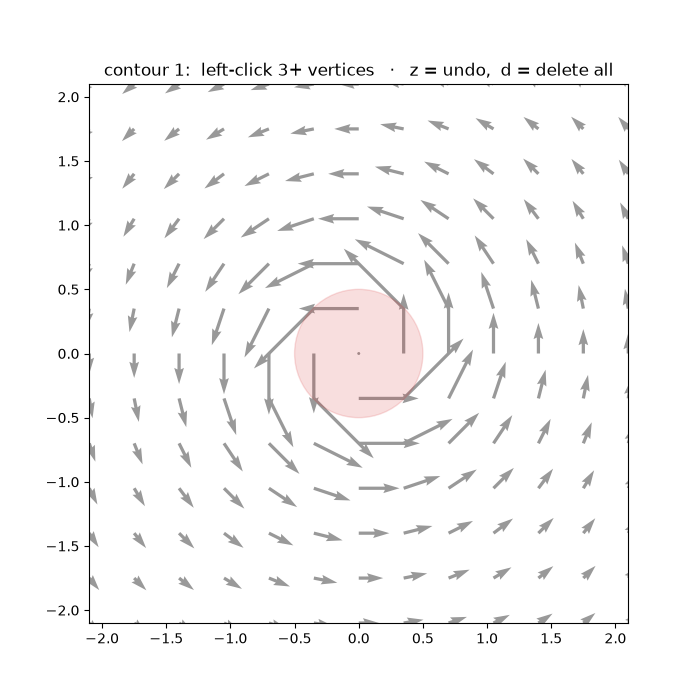

In [9]:
%matplotlib widget
# %matplotlib tk      # <- use this instead if the inline canvas does not appear

fig, ax = plt.subplots(figsize=(7, 7))
arrows(ax, vortex, 0, (-2.1, 2.1), (-2.1, 2.1), nx=13, ny=13)
ax.add_patch(plt.Circle((0, 0), A, color='C3', alpha=0.15))
ax.set(xlim=(-2.1, 2.1), ylim=(-2.1, 2.1), aspect='equal')

pts     = []                                   # the contour being drawn
kept    = []                                   # (gamma, line, label) for each finished one
COLOURS = ['C0', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
live,   = ax.plot([], [], 'o--', color='k', lw=1.5, ms=5)

def gamma_of(xs, ys):
    return circulation(vortex, *refine(xs, ys))     # refine: see the note above

def redraw():
    xs = np.array([p[0] for p in pts]); ys = np.array([p[1] for p in pts])
    if len(pts) >= 3:
        live.set_data(np.append(xs, xs[0]), np.append(ys, ys[0]))
        ax.set_title(f'contour {len(kept)+1}:  {len(pts)} vertices,  '
                     f'$\Gamma$ = {gamma_of(xs, ys):+.3f}      '
                     f'(right-click to keep it and start another)')
    else:
        live.set_data(xs, ys)
        ax.set_title(f'contour {len(kept)+1}:  left-click 3+ vertices   ·   '
                     f'z = undo,  d = delete all')
    fig.canvas.draw_idle()

def keep_current():
    """Freeze the contour being drawn and leave it on the plot."""
    xs = np.array([p[0] for p in pts]); ys = np.array([p[1] for p in pts])
    G = gamma_of(xs, ys)
    c = COLOURS[len(kept) % len(COLOURS)]
    ln, = ax.plot(np.append(xs, xs[0]), np.append(ys, ys[0]), lw=2, color=c)
    top = int(np.argmax(ys))          # label the highest vertex, so concentric
                                      # contours do not print on top of each other
    tx = ax.annotate(f'$\Gamma$={G:+.2f}', (xs[top], ys[top]),
                     xytext=(0, 6), textcoords='offset points', color=c,
                     ha='center', va='bottom', fontsize=10, fontweight='bold')
    kept.append((G, ln, tx))
    print(f'contour {len(kept)}:  {len(xs)} vertices   Gamma = {G:+.4f}'
          f'   ({G/GAMMA:+.2f} x the vortex)')
    pts.clear()

def delete_all():
    for _, ln, tx in kept:
        ln.remove(); tx.remove()
    kept.clear(); pts.clear()

def on_click(event):
    if event.inaxes is not ax:
        return
    if event.button == 3:                      # right-click: keep it, start a new one
        if len(pts) >= 3:
            keep_current()
    else:
        pts.append((event.xdata, event.ydata))
    redraw()

def on_key(event):
    if event.key == 'd':
        delete_all()
    elif event.key == 'z' and pts:
        pts.pop()
    redraw()

fig.canvas.mpl_connect('button_press_event', on_click)
fig.canvas.mpl_connect('key_press_event', on_key)
redraw()
plt.show()

No clicking? The same thing by hand — type the vertices and integrate:

```python
xs, ys = np.array([-1.4, 1.6, 1.2, -0.9]), np.array([-1.1, -1.5, 1.3, 1.6])
print(circulation(vortex, *refine(xs, ys)))
```